## 1. Загрузка

In [2]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path('data/online_shoppers_intention.csv')
df = pd.read_csv(DATA_PATH)
print('Строк и столбцов:', df.shape)
df.head(3)

Строк и столбцов: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.0,0.0,0.1,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False


In [3]:
df.dtypes

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object

In [4]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


# Гипотезы
1. В данных присутствует дисбаланс классов. Сессий с покупками сильно меньше, чем без покупок. Поэтому показания roc auc будут завышены.
2. Есть бесполезные признаки. Логистическая регрессия с lasso регуляризацей их занулит. Дерево покажет, что они не важны.
3. Есть коррелирующие признаки.
4. Дерево покажет лучшие метрики на тесте.
5. Данные могут быть зависимые, то есть несколько стрчек это сессии одного и того же пользователя.

In [24]:
import sklearn
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Revenue'])
y = df["Revenue"]
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=42, stratify=y_train_val)

In [25]:
for name, X_part, y_part in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test),
]:
    print(name, X_part.shape, y_part.shape)
    print(y_part.value_counts(normalize=True))

train (7891, 17) (7891,)
Revenue
False    0.845267
True     0.154733
Name: proportion, dtype: float64
validation (1973, 17) (1973,)
Revenue
False    0.845413
True     0.154587
Name: proportion, dtype: float64
test (2466, 17) (2466,)
Revenue
False    0.845093
True     0.154907
Name: proportion, dtype: float64


# EDA

In [31]:
for name, X_part, y_part in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test),
]:
    print(f"пропуски в {name} данных:\n", X_part.isna().sum())
    print(f"пропуски в {name} тагретах:\n", y_part.isna().sum())
    print()

пропуски в train данных:
 Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
dtype: int64
пропуски в train тагретах:
 0

пропуски в validation данных:
 Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0


Пропуски заполнять не нужно

In [62]:
CAT_COLUMNS = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",                  
    "Region",
    "TrafficType"
]
ORD_COLUMNS = []

VALUE_COLUMNS = [
    col for col in X_train.columns
    if col not in CAT_COLUMNS + ORD_COLUMNS
]

In [63]:
print("Категорильные признаки:")
display(X_train.loc[:, CAT_COLUMNS])
for col in CAT_COLUMNS:
    print(f"\n{col}:")
    print(X_train[col].value_counts(dropna=False))


Категорильные признаки:


,Month,VisitorType,Weekend,OperatingSystems,Browser,Region,TrafficType
8318,Nov,Returning_Visitor,True,1,1,1,3
3642,May,Returning_Visitor,True,2,2,7,4
2517,May,Returning_Visitor,False,2,10,3,4
2946,May,Returning_Visitor,False,2,2,6,6
3483,May,Returning_Visitor,True,3,2,8,4
...,...,...,...,...,...,...,...
6833,Oct,Returning_Visitor,False,2,4,1,1
4649,May,Returning_Visitor,False,1,1,3,4
7465,Jul,Returning_Visitor,False,3,3,3,4
9226,Dec,Returning_Visitor,True,2,4,1,2



Month:
Month
May     2183
Nov     1857
Mar     1249
Dec     1109
Oct      347
Sep      297
Jul      274
Aug      271
June     191
Feb      113
Name: count, dtype: int64

VisitorType:
VisitorType
Returning_Visitor    6750
New_Visitor          1082
Other                  59
Name: count, dtype: int64

Weekend:
Weekend
False    6066
True     1825
Name: count, dtype: int64

OperatingSystems:
OperatingSystems
2    4228
3    1660
1    1644
4     281
8      56
6      13
5       5
7       4
Name: count, dtype: int64

Browser:
Browser
2     5085
1     1546
4      490
5      302
6      110
10     108
8       93
3       73
13      41
7       32
12       5
11       5
9        1
Name: count, dtype: int64

Region:
Region
1    3020
3    1544
4     756
2     750
6     519
7     479
9     335
8     271
5     217
Name: count, dtype: int64

TrafficType:
TrafficType
2     2497
1     1534
3     1339
4      697
13     455
6      294
10     292
8      217
5      168
11     166
20     119
7       30
9       2

In [64]:
print("Числовые признаки:")
display(X_train.loc[:, VALUE_COLUMNS])
display(X_train.loc[:, VALUE_COLUMNS].describe())

Числовые признаки:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
8318,0,0.000000,0,0.0,2,0.000000,0.200000,0.200000,0.000000,0.0
3642,4,237.833333,0,0.0,66,3268.075758,0.005882,0.029549,0.000000,1.0
2517,0,0.000000,0,0.0,5,331.333333,0.053333,0.096000,0.000000,0.0
2946,0,0.000000,0,0.0,18,521.500000,0.022222,0.063333,0.000000,0.0
3483,0,0.000000,0,0.0,3,105.250000,0.000000,0.044444,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...
6833,11,104.973333,2,41.2,27,572.873333,0.000000,0.011111,23.550439,0.0
4649,1,174.000000,0,0.0,9,272.000000,0.013333,0.073333,0.000000,0.0
7465,4,47.800000,0,0.0,7,183.000000,0.018182,0.072727,0.000000,0.0
9226,0,0.000000,0,0.0,9,79.750000,0.000000,0.025000,0.000000,0.0


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
count,7891.000000,7891.000000,7891.000000,7891.000000,7891.000000,7891.000000,7891.000000,7891.000000,7891.000000,7891.000000
mean,2.286909,79.375918,0.509695,35.325821,31.173362,1180.705761,0.022801,0.043883,5.951677,0.065137
std,3.326211,179.237207,1.293055,143.897145,43.223299,1949.843464,0.049341,0.049346,18.863278,0.204846
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,179.979167,0.000000,0.014286,0.000000,0.000000
50%,1.000000,6.000000,0.000000,0.000000,17.000000,595.750000,0.003191,0.025714,0.000000,0.000000
75%,4.000000,89.990000,0.000000,0.000000,38.000000,1464.313143,0.017521,0.050000,0.000000,0.000000
max,24.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000


Категориальные признаки нужно закаодировать

Для логистической регрессии проверим масштабирование числовых признаков. Дерево будем обучать без него.

Распределние Informational_Duration, Administrative_Duration, ProductRelated, ProductRelated_Duration имеют очень длинный правый хвост 

Категориальные признаки имеют редкие значения.



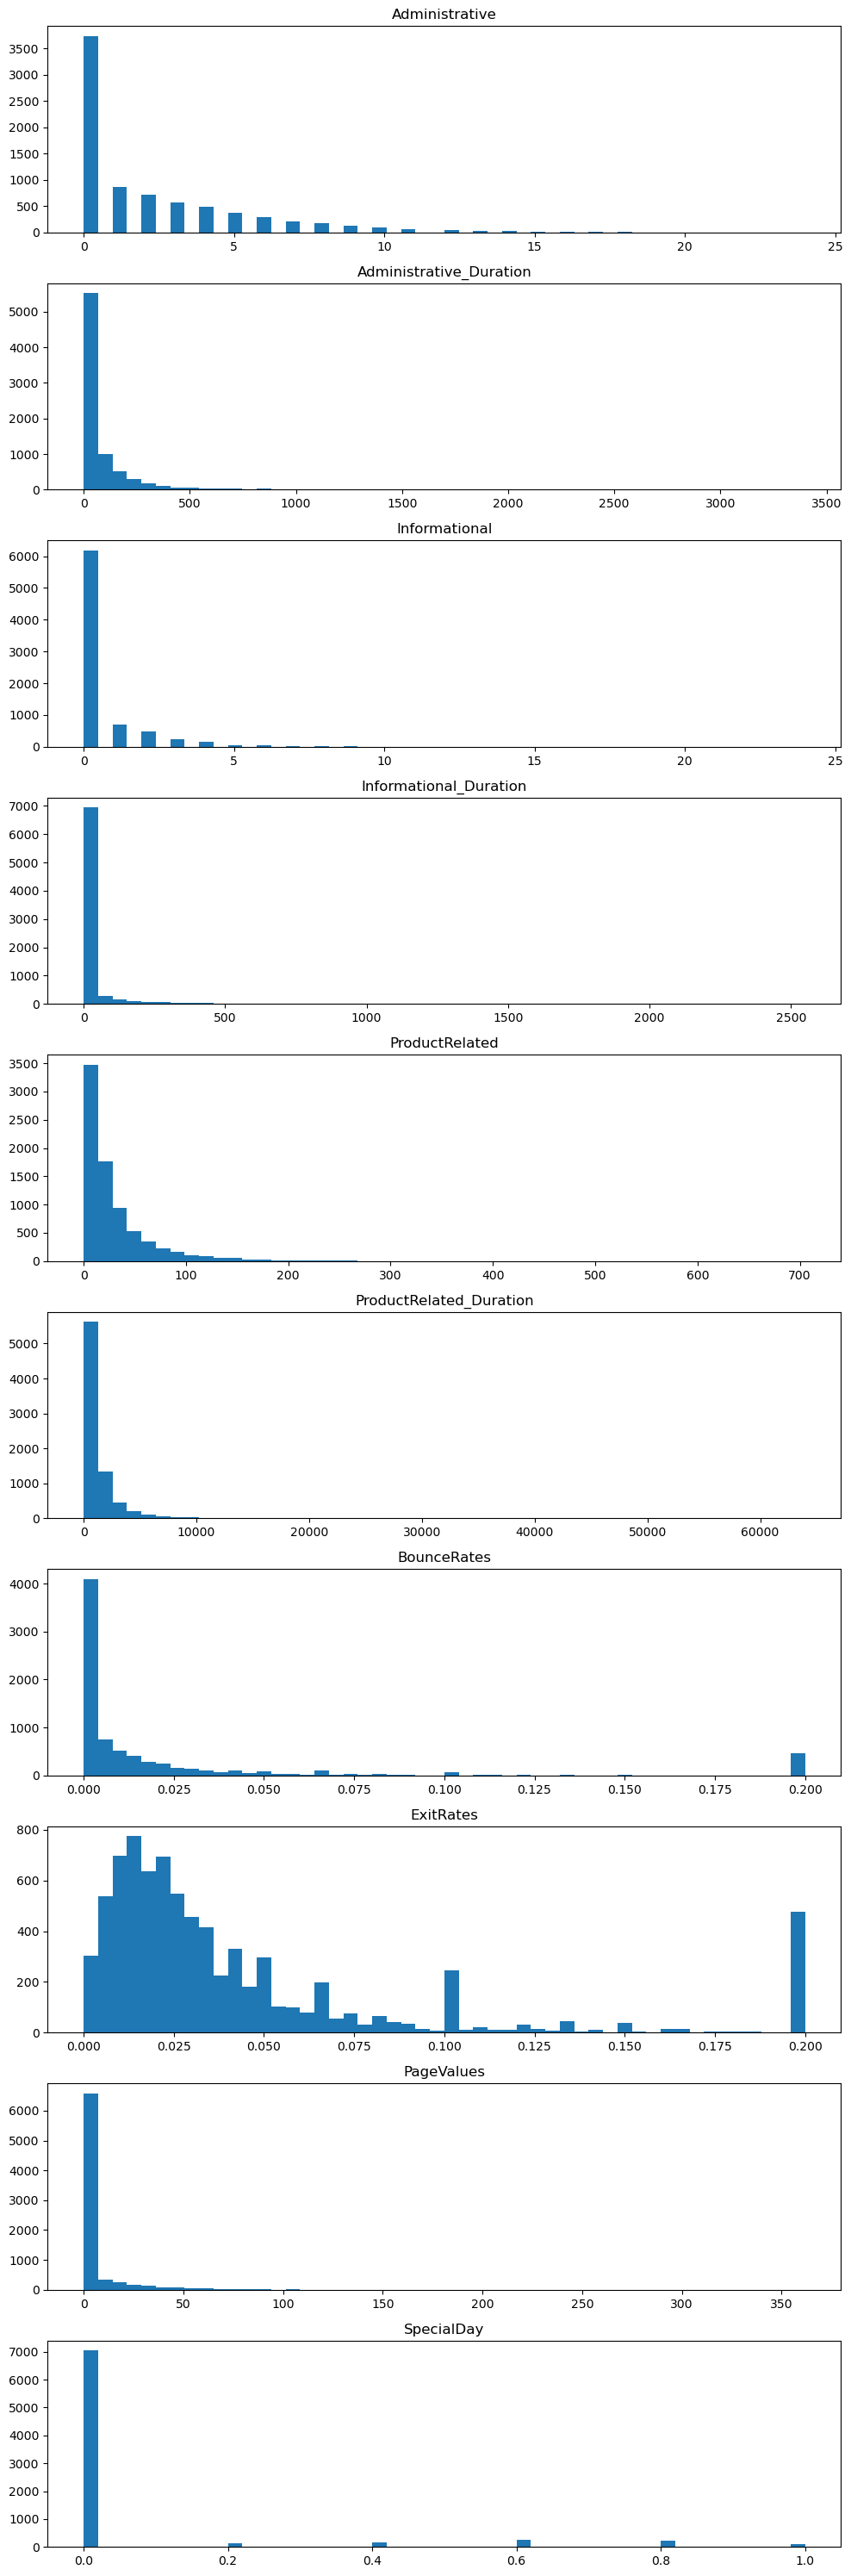

In [97]:
import numpy as np
import matplotlib.pyplot as plt
fig, axes = plt.subplots(
    len(VALUE_COLUMNS), 1,
    figsize=(10, 3 * len(VALUE_COLUMNS)),
)
for i, col in enumerate(VALUE_COLUMNS):
    axes[i].set_title(col)
    axes[i].hist(X_train[col], bins=50)
plt.tight_layout()
plt.show()

Распеделения почти всех чиловых призноков имеют длинный хвост, поэтому применим преобразование log1p в логистической регессии в качетве эксперимента. 

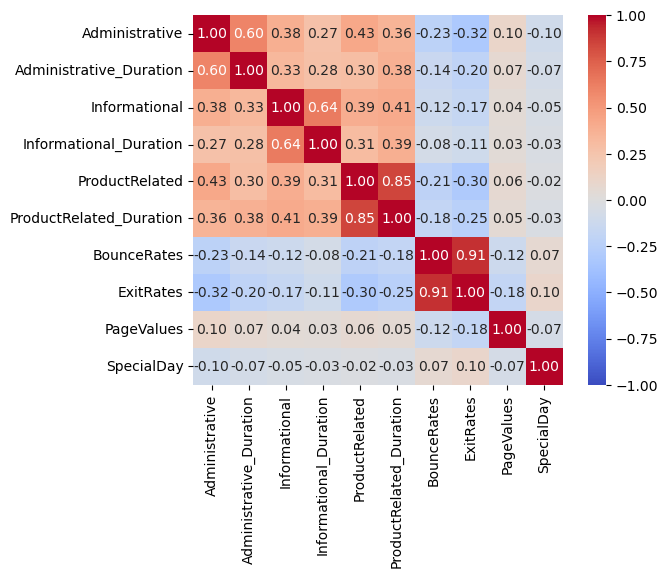

In [105]:
import seaborn as sns
corr = X_train[VALUE_COLUMNS].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', square=True, vmin=-1, vmax=1, center=0);

BounceRates сильно коррелирует с ExitRates, RroductRelated сильно коррелирует с RroductRelated_Duration, для логистической регрессии можно убрать коррелирующие признаки в качестве эксперимента. 

# обучение базовый logreg

In [107]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression


In [124]:

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), VALUE_COLUMNS),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_COLUMNS)
    ]
)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression())
])

In [125]:
pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Administrative',
                                                   'Administrative_Duration',
                                                   'Informational',
                                                   'Informational_Duration',
                                                   'ProductRelated',
                                                   'ProductRelated_Duration',
                                                   'BounceRates', 'ExitRates',
                                                   'PageValues',
                                                   'SpecialDay']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Month', 'VisitorType',
                                                   'Weekend',
                                                   'OperatingSystems',
                                                   'Browser', 'Region',
                                                   'TrafficType'])])),
                ('classifier', LogisticRegression())])

In [ ]:
def evaluate(model, X, y):
    pred = model.predict(X)
    score = model.predict_proba(X)[:, 1]

    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, score),
        "average_precision": average_precision_score(y, score),
    }, pred

In [ ]:

metrics, y_pred = evaluate(pipeline, X_val, y_val)
display(pd.Series(metrics).round(4))

display(pd.DataFrame(
    confusion_matrix(y_val, y_pred, labels=[False, True]),
    index=["На самом деле: нет покупки", "На самом деле: покупка"],
    columns=["Предсказано: нет покупки", "Предсказано: покупка"],
))

accuracy             0.8824
precision            0.7239
recall               0.3869
f1                   0.5043
roc_auc              0.8827
average_precision    0.6404
dtype: float64

,Предсказано: нет покупки,Предсказано: покупка
На самом деле: нет покупки,1623,45
На самом деле: покупка,187,118


roc_auc завышенный. Видим что recall низкий, то есть среди всех покупок модель находит далеко не все случаи.
precision высокий, то есть если модель уверена, что покупака состоялась, то она права.

# Обучение logreg с преобразованиями и регуляризацией

In [145]:
from sklearn.preprocessing import FunctionTransformer

LOG_CANDIDATES = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "PageValues"
]
DROP_COLUMNS = ["BounceRates", "ProductRelated"]

log_columns = [
    col for col in LOG_CANDIDATES
    if col not in DROP_COLUMNS
]

numeric_columns = [
    col for col in VALUE_COLUMNS
    if col not in DROP_COLUMNS and col not in log_columns
]

log_pipeline = Pipeline([
    ("log1p", FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one",
    )),
    ("scaler", StandardScaler()),
])


preprocessor_smart = ColumnTransformer(
    transformers=[
        ("log_numeric", log_pipeline, log_columns),
        ("other_numeric", StandardScaler(), numeric_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), CAT_COLUMNS),
    ],
    remainder="drop",
)

pipeline_smart = Pipeline(steps=[
    ('preprocessor', preprocessor_smart),
    ('classifier', LogisticRegression(max_iter=2000))
])

In [146]:
pipeline_smart.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('log_numeric',
                                                  Pipeline(steps=[('log1p',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Administrative_Duration',
                                                   'Informational_Duration',
                                                   'ProductRelated_Duration',
                                                   'PageValues']),
                                                 ('other_numeric',
                                                  StandardScaler(),
                                                  ['Administrative',
                                                   'Informational', 'ExitRates',
                                                   'SpecialDay']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Month', 'VisitorType',
                                                   'Weekend',
                                                   'OperatingSystems',
                                                   'Browser', 'Region',
                                                   'TrafficType'])])),
                ('classifier', LogisticRegression(max_iter=2000))])

In [147]:
metrics_smart, y_pred = evaluate(pipeline_smart, X_val, y_val)
display(pd.Series(metrics_smart).round(4))

display(pd.DataFrame(
    confusion_matrix(y_val, y_pred, labels=[False, True]),
    index=["На самом деле: нет покупки", "На самом деле: покупка"],
    columns=["Предсказано: нет покупки", "Предсказано: покупка"],
))

accuracy             0.8956
precision            0.7037
recall               0.5607
f1                   0.6241
roc_auc              0.9103
average_precision    0.6848
dtype: float64

,Предсказано: нет покупки,Предсказано: покупка
На самом деле: нет покупки,1596,72
На самом деле: покупка,134,171


Таким образом, преобразования помогли увеличить количество верно определенных сессий с покупками, recall вырос, но precision немного уменьшился.

# Эксперимент с lasso регуляризацией.
Проверим занулятся ли какие-нибудь признаки

In [176]:

pipeline_lasso = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier_lasso', LogisticRegression(penalty='l1', solver='liblinear'))
])

In [177]:
pipeline_lasso.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Administrative',
                                                   'Administrative_Duration',
                                                   'Informational',
                                                   'Informational_Duration',
                                                   'ProductRelated',
                                                   'ProductRelated_Duration',
                                                   'BounceRates', 'ExitRates',
                                                   'PageValues',
                                                   'SpecialDay']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Month', 'VisitorType',
                                                   'Weekend',
                                                   'OperatingSystems',
                                                   'Browser', 'Region',
                                                   'TrafficType'])])),
                ('classifier_lasso',
                 LogisticRegression(penalty='l1', solver='liblinear'))])

In [178]:

metrics, y_pred = evaluate(pipeline_lasso, X_val, y_val)
display(pd.Series(metrics).round(4))

display(pd.DataFrame(
    confusion_matrix(y_val, y_pred, labels=[False, True]),
    index=["На самом деле: нет покупки", "На самом деле: покупка"],
    columns=["Предсказано: нет покупки", "Предсказано: покупка"],
))

print("Коэффициента признаков:")

accuracy             0.8824
precision            0.7239
recall               0.3869
f1                   0.5043
roc_auc              0.8831
average_precision    0.6403
dtype: float64

,Предсказано: нет покупки,Предсказано: покупка
На самом деле: нет покупки,1623,45
На самом деле: покупка,187,118


Коэффициента признаков:


In [188]:
feature_weights = pd.DataFrame(
    pipeline_lasso['classifier_lasso'].coef_[0], 
    index=pipeline_lasso["preprocessor"].get_feature_names_out(), 
    columns=['weight']
)
display(
    feature_weights.loc[feature_weights["weight"] == 0]
)
print(f"Занулилось {feature_weights.loc[feature_weights["weight"] == 0].shape[0]} признаков")

,weight
cat__Month_Aug,0.0
cat__Month_June,0.0
cat__Month_Sep,0.0
cat__VisitorType_New_Visitor,0.0
cat__VisitorType_Other,0.0
cat__Weekend_True,0.0
cat__OperatingSystems_4,0.0
cat__OperatingSystems_5,0.0
cat__OperatingSystems_6,0.0
cat__OperatingSystems_7,0.0


Занулилось 27 признаков


Эксперимент с lasso на базовых преобразованиях, показал что занулились только добавленные категориальные признаки. Коэффициенты числовых признаков остались ненулевыми. Заметного улучшения качества на validation относительно базовой модели нет.

# Обучение дерева
Для дерева не нужны осбенные преобразования признаков. Поэтому обучим его на исходных данных

In [208]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", VALUE_COLUMNS),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), CAT_COLUMNS),
    ],
    remainder="drop",

)

tree_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42)),
])

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)

tree_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid={
        "classifier__max_depth": [3, 5, 8, None],
        "classifier__min_samples_leaf": [1, 10],
    },
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)

tree_search.fit(X_train, y_train)
print("Лучшие параметры:", tree_search.best_params_)
print("Средняя AP на CV:", tree_search.best_score_)

tree_model = tree_search.best_estimator_

train_metrics, _ = evaluate(tree_model, X_train, y_train)
val_metrics, y_pred = evaluate(tree_model, X_val, y_val)

display(pd.DataFrame({
    "train": train_metrics,
    "validation": val_metrics,
}).round(4))

display(pd.DataFrame(
    confusion_matrix(y_val, y_pred, labels=[False, True]),
    index=["На самом деле: нет покупки", "На самом деле: покупка"],
    columns=["Предсказано: нет покупки", "Предсказано: покупка"],
))

Лучшие параметры: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 10}
Средняя AP на CV: 0.6723152885892945


,train,validation
accuracy,0.9118,0.9027
precision,0.7612,0.7251
recall,0.6265,0.5967
f1,0.6873,0.6547
roc_auc,0.9303,0.9219
average_precision,0.7334,0.7092


,Предсказано: нет покупки,Предсказано: покупка
На самом деле: нет покупки,1599,69
На самом деле: покупка,123,182


Метрики дерева превосходят метрики и базовой линейной регрессии и линейной регрессии с преобразованиями.

Посмотрим на важности признаков от дерева

numeric__Administrative: 0.028518043034630847
numeric__Administrative_Duration: 0.00545446143376943
numeric__Informational: 0.005922860269826383
numeric__Informational_Duration: 0.00034053709543638234
numeric__ProductRelated: 0.005411510534371102
numeric__ProductRelated_Duration: 0.047457765621878895
numeric__BounceRates: 0.07750546195359899
numeric__ExitRates: 0.010720432498535123
numeric__PageValues: 0.7655284627969604
numeric__SpecialDay: 0.0
categorical__Month_Aug: 0.0
categorical__Month_Dec: 0.0
categorical__Month_Feb: 0.0
categorical__Month_Jul: 0.0
categorical__Month_June: 0.0
categorical__Month_Mar: 0.007557488614579144
categorical__Month_May: 0.0
categorical__Month_Nov: 0.042789429894966736
categorical__Month_Oct: 0.0
categorical__Month_Sep: 0.0
categorical__VisitorType_New_Visitor: 0.0
categorical__VisitorType_Other: 0.0
categorical__VisitorType_Returning_Visitor: 0.0
categorical__Weekend_False: 0.0
categorical__Weekend_True: 0.0
categorical__OperatingSystems_1: 0.0
categoric

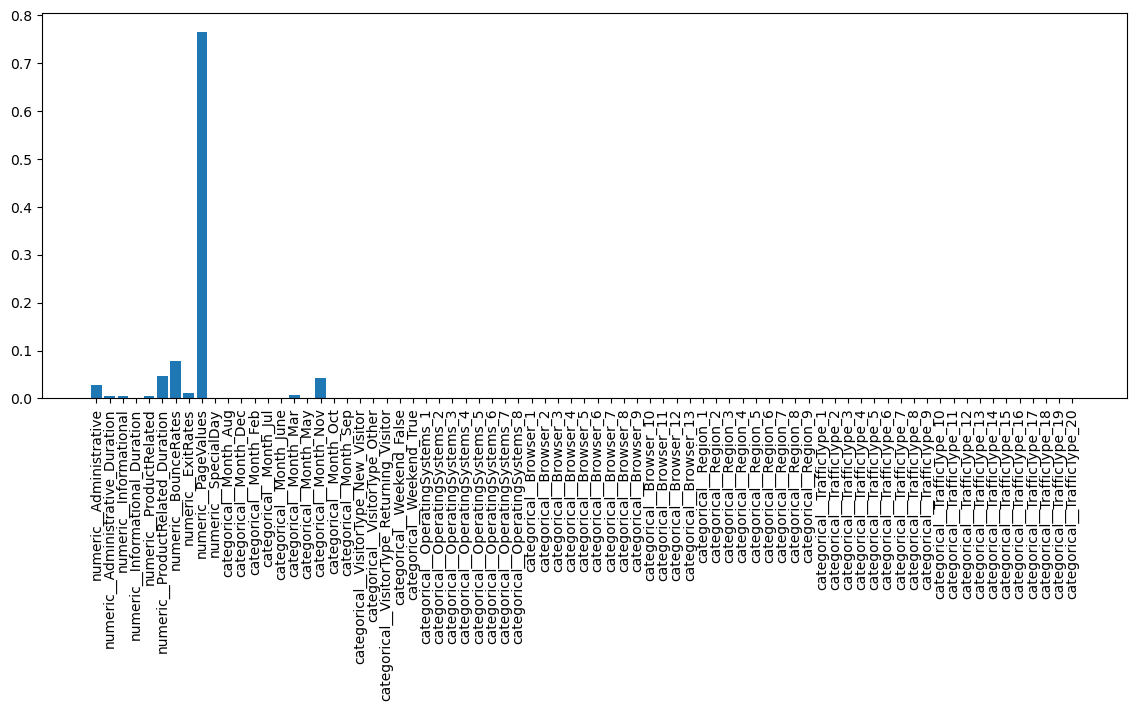

In [209]:

importances = tree_model['classifier'].feature_importances_

for feature_name, importance in zip(tree_model['preprocessor'].get_feature_names_out(), importances):
  print(f'{feature_name}: {importance}')

fix, ax = plt.subplots(1, figsize=(14, 5))
ax.bar(tree_model['preprocessor'].get_feature_names_out(), importances)
ax.tick_params(axis='x', rotation=90)
plt.show()


Самый важный признак для этого дерева это PageValues. Большинство категориальных признаков дерево вообще не использовало.

# Окончательная оценка на test

In [210]:
from sklearn.base import clone

final_model = clone(tree_model)
final_model.fit(X_train_val, y_train_val)

test_metrics, test_pred = evaluate(final_model, X_test, y_test)
display(pd.Series(test_metrics).round(4))

display(pd.DataFrame(
    confusion_matrix(y_test, test_pred, labels=[False, True]),
    index=["На самом деле: нет покупки", "На самом деле: покупка"],
    columns=["Предсказано: нет покупки", "Предсказано: покупка"],
))

accuracy             0.8990
precision            0.7111
recall               0.5864
f1                   0.6428
roc_auc              0.9175
average_precision    0.6858
dtype: float64

,Предсказано: нет покупки,Предсказано: покупка
На самом деле: нет покупки,1993,91
На самом деле: покупка,158,224


# Выводы по гипотезам:
1. Дисбаланс есть. roc auc действительно показывал очень хорошие цифры, при явных проблемах с предсказаниями.
2. Ни lasso, ни важности признаков в дереве не зануляли исходные признаки, только добавленные onehot признаки.
3. Наличие корреляций между признаками подтвердилось, но все коррелирующие признаки несли в себе дополнительную информаци для моделей, так как ни один метод их не занулил.
4. Дерево действительно превзошло по метрики логистическую регрессию. И не потребовало допольнительно предоборадотки признаков.
5. По имеющимся данным не удалось проверить есть ли зависимости межу строчками датасета, так как в признаках отсутствуют id пользователей.